
# University of Salford - SalfordX
**Machine Learning-based Charge-Point Forecasting Tool (CPFT) for forecasting the charge demand and availability of EV charge-points.**



**Project Overview**

This project leverages CPFT to forecast the charge demand and availability of Electric Vehicle (EV) charge-points. Using historical data from EV charge-point stations, this model predicts both the availability of stations (whether they are in use or not) and the kWh delivered per hour. The model utilizes a Long Short-Term Memory (LSTM) network for sequential data prediction, designed to capture temporal dependencies in the dataset.

**File Structure**

The code is structured as follows:

*   **Data Preprocessing**: The data is loaded, cleaned, and transformed to extract key features such as time, charge amount, and availability.
*   **Feature Engineering**: Additional features such as day type (weekday/weekend) and month are added. A full range of hourly data is merged with the existing dataset, with missing values filled where necessary.
*   **Modeling**: The LSTM model is built and trained to forecast both the availability of charge stations and the kWh delivered per hour.
*   **Evaluation**: The model's performance is evaluated using metrics such as MSE, RMSE, MAE, and R². It also includes visualizations of the predicted vs. actual data for both availability and kWh delivered.
*   **Prediction**: The trained model is used to forecast future availability and charge demand for the next 24 hours.

In [1]:
#!pip install numpy pandas matplotlib scikit-learn tensorflow openpyxl ipython jupyter

In [2]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    roc_auc_score, f1_score, precision_score, recall_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import FileLink, display


# -----------------------------
# Load data
# -----------------------------
file_path = "/content/Station_2_39_139_28.csv"  # adjust if needed
data = pd.read_csv(file_path)

# Forecast horizon (number of hours to predict ahead)
Forecast_period = 168

# -----------------------------
# Excel-safe timezone
# -----------------------------
def make_excel_safe(df: pd.DataFrame) -> pd.DataFrame:
    df2 = df.copy()
    for c in df2.columns:
        if pd.api.types.is_datetime64tz_dtype(df2[c]):
            df2[c] = df2[c].dt.tz_convert("UTC").dt.tz_localize(None)
    return df2

# -----------------------------
# Availability model
# -----------------------------

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
class BinaryAvailabilityModel(keras.Model):
    def __init__(self, seq_len, n_features, last_hour_index, lag1_mu, lag1_std, blend_init=-2.0):
        super().__init__()
        self.seq_len = int(seq_len)
        self.n_features = int(n_features)
        self.last_hour_index = int(last_hour_index)

        # store scaler stats for availability_lag1 (so we can convert scaled -> raw)
        self.lag1_mu  = tf.constant(float(lag1_mu), dtype=tf.float32)
        self.lag1_std = tf.constant(float(lag1_std), dtype=tf.float32)

        # Backbone outputs LOGITS (no sigmoid here)
        self.backbone = keras.Sequential([
            layers.Input(shape=(self.seq_len, self.n_features)),
            layers.Conv1D(64, 3, padding="causal", activation="relu"),
            layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
            layers.Dropout(0.2),
            layers.Bidirectional(layers.LSTM(32)),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.2),
            layers.Dense(1)  # logits
        ])

        # Learnable blend weight for Last-Hour baseline: w = sigmoid(blend_logit) in [0,1]
        self.blend_logit = self.add_weight(
            name="blend_logit",
            shape=(),
            initializer=tf.keras.initializers.Constant(blend_init),
            trainable=True,
            dtype=tf.float32
        )

        # Trackers
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.mse_metric   = keras.metrics.MeanSquaredError(name="mse")
        self.mae_metric   = keras.metrics.MeanAbsoluteError(name="mae")

    def _blend_with_last_hour(self, x, prob_model):
        # x contains SCALED features → unscale availability_lag1 back to raw
        lag1_scaled = x[:, -1, self.last_hour_index]
        lag1_raw = lag1_scaled * self.lag1_std + self.lag1_mu   # approx 0..1

        last_hour = tf.clip_by_value(lag1_raw, 0.0, 1.0)
        last_hour = tf.reshape(last_hour, (-1, 1))

        w = tf.sigmoid(self.blend_logit)  # 0..1
        prob_final = w * last_hour + (1.0 - w) * prob_model
        return prob_final

    def call(self, x, training=None):
        logits = self.backbone(x, training=training)
        prob_model = tf.sigmoid(logits)
        prob_final = self._blend_with_last_hour(x, prob_model)
        return prob_final

    @property
    def metrics(self):
        return [self.loss_tracker, self.mse_metric, self.mae_metric]

    def train_step(self, data):
        x, y = data
        y = tf.cast(tf.reshape(y, (-1, 1)), tf.float32)

        with tf.GradientTape() as tape:
            prob = self(x, training=True)
            loss = tf.reduce_mean(tf.square(y - prob))  # MSE (Brier score)

        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))

        self.loss_tracker.update_state(loss)
        self.mse_metric.update_state(y, prob)
        self.mae_metric.update_state(y, prob)

        return {"loss": self.loss_tracker.result(),
                "mse": self.mse_metric.result(),
                "mae": self.mae_metric.result()}

    def test_step(self, data):
        x, y = data
        y = tf.cast(tf.reshape(y, (-1, 1)), tf.float32)

        prob = self(x, training=False)
        loss = tf.reduce_mean(tf.square(y - prob))

        self.loss_tracker.update_state(loss)
        self.mse_metric.update_state(y, prob)
        self.mae_metric.update_state(y, prob)

        return {"loss": self.loss_tracker.result(),
                "mse": self.mse_metric.result(),
                "mae": self.mae_metric.result()}

    def predict_proba(self, x, batch_size=256):
        return self.predict(x, batch_size=batch_size, verbose=0).reshape(-1)

# -----------------------------
# 1) Preprocess sessions
# -----------------------------
file_path = "/content/Station_2_39_139_28.csv"  # adjust if needed
data = pd.read_csv(file_path)

required = ["connectionTime", "disconnectTime", "doneChargingTime", "kWhDelivered"]
missing = [c for c in required if c not in data.columns]
if missing:
    if len(data.columns) == 13:
        data.columns = [
            "StationID","clusterID","connectionTime","disconnectTime","doneChargingTime",
            "kWhDelivered","sessionID","siteID","spaceID","stationID","timezone","userID","userInputs"
        ]
    else:
        raise ValueError(f"Missing required columns: {missing}. Columns found: {data.columns.tolist()}")

for c in ["connectionTime", "disconnectTime", "doneChargingTime"]:
    data[c] = pd.to_datetime(data[c], errors="coerce", utc=True)

data["kWhDelivered"] = pd.to_numeric(data["kWhDelivered"], errors="coerce")

data_clean = data.dropna(subset=["connectionTime","disconnectTime","kWhDelivered"]).copy()
data_clean = data_clean[data_clean["disconnectTime"] > data_clean["connectionTime"]].copy()

data_clean["chargeEndTime"] = data_clean["doneChargingTime"].fillna(data_clean["disconnectTime"])
data_clean.loc[data_clean["kWhDelivered"] < 0, "kWhDelivered"] = 0.0

print("Sessions cleaned:", data_clean.shape)

# -----------------------------
# 2) Build hourly dataset
# -----------------------------
def build_hourly_frame(sessions: pd.DataFrame) -> pd.DataFrame:
    start = sessions["connectionTime"].min().floor("H")
    end   = sessions["disconnectTime"].max().ceil("H")
    hours = pd.date_range(start=start, end=end, freq="H", tz="UTC")

    hourly = pd.DataFrame({"hour": hours})
    hourly["availability"] = 0
    hourly["occupancy_count"] = 0
    hourly["connected_minutes"] = 0.0
    hourly["kWhDelivered"] = 0.0

    hour_start = hourly["hour"].values.astype("datetime64[ns]")
    hour_end   = (hourly["hour"] + pd.Timedelta(hours=1)).values.astype("datetime64[ns]")

    def add_overlap(interval_start, interval_end, value_per_session=None, mode="binary_or_count"):
        interval_start = np.asarray(interval_start).astype("datetime64[ns]")
        interval_end   = np.asarray(interval_end).astype("datetime64[ns]")
        if value_per_session is not None:
            value_per_session = np.asarray(value_per_session, dtype=float)

        n_h = len(hourly)

        for i in range(len(interval_start)):
            s_ns = interval_start[i]
            e_ns = interval_end[i]
            if np.isnat(s_ns) or np.isnat(e_ns) or e_ns <= s_ns:
                continue

            left = np.searchsorted(hour_end, s_ns, side="right") - 1
            right = np.searchsorted(hour_start, e_ns, side="left")

            left = max(left, 0)
            right = min(right, n_h)
            if right <= left:
                continue

            total_sec = (e_ns - s_ns) / np.timedelta64(1, "s")
            if total_sec <= 0:
                continue

            for h in range(left, right):
                hs = hour_start[h]
                he = hour_end[h]

                overlap_start = hs if hs > s_ns else s_ns
                overlap_end   = he if he < e_ns else e_ns
                overlap_sec = (overlap_end - overlap_start) / np.timedelta64(1, "s")
                if overlap_sec <= 0:
                    continue

                if mode == "binary_or_count":
                    hourly.at[h, "availability"] = 1
                    hourly.at[h, "occupancy_count"] += 1
                elif mode == "minutes":
                    hourly.at[h, "connected_minutes"] += overlap_sec / 60.0
                elif mode == "kwh":
                    kwh_i = float(value_per_session[i])
                    hourly.at[h, "kWhDelivered"] += kwh_i * (overlap_sec / total_sec)

    conn   = sessions["connectionTime"].values.astype("datetime64[ns]")
    disc   = sessions["disconnectTime"].values.astype("datetime64[ns]")
    ch_end = sessions["chargeEndTime"].values.astype("datetime64[ns]")
    kwh    = sessions["kWhDelivered"].values.astype(float)

    add_overlap(conn, disc, mode="binary_or_count")
    add_overlap(conn, disc, mode="minutes")
    add_overlap(conn, ch_end, value_per_session=kwh, mode="kwh")

    dt = hourly["hour"]
    hourly["hour_of_day"] = dt.dt.hour
    hourly["day_of_week"] = dt.dt.dayofweek
    hourly["day_type"] = (hourly["day_of_week"] >= 5).astype(int)
    hourly["month"] = dt.dt.month

    hourly["hod_sin"] = np.sin(2*np.pi*hourly["hour_of_day"]/24)
    hourly["hod_cos"] = np.cos(2*np.pi*hourly["hour_of_day"]/24)
    hourly["dow_sin"] = np.sin(2*np.pi*hourly["day_of_week"]/7)
    hourly["dow_cos"] = np.cos(2*np.pi*hourly["day_of_week"]/7)
    hourly["mon_sin"] = np.sin(2*np.pi*(hourly["month"]-1)/12)
    hourly["mon_cos"] = np.cos(2*np.pi*(hourly["month"]-1)/12)

    hourly["kWhDelivered"] = hourly["kWhDelivered"].clip(lower=0)
    return hourly

kWh_full_raw = build_hourly_frame(data_clean)
print("Hourly dataset:", kWh_full_raw.shape)
print(kWh_full_raw[["hour","availability","occupancy_count","connected_minutes","kWhDelivered"]].head())

# -----------------------------
# 1.5 Outlier handling (train-only stats)
# -----------------------------
def zscore_filter_train_only(df, cols, train_frac=0.60, threshold=3.0, mode="clip"):
    df = df.copy()
    n_train = int(len(df) * train_frac)
    train_df = df.iloc[:n_train]

    stats = {}
    for c in cols:
        mu = train_df[c].mean()
        sd = train_df[c].std()
        if sd == 0 or np.isnan(sd):
            sd = 1e-9
        stats[c] = (mu, sd)

        if mode == "clip":
            lo = mu - threshold * sd
            hi = mu + threshold * sd
            df[c] = df[c].clip(lower=lo, upper=hi)

    return df, stats

outlier_cols = ["kWhDelivered", "connected_minutes"]
kWh_full_raw, z_stats = zscore_filter_train_only(
    kWh_full_raw, cols=outlier_cols, train_frac=0.60, threshold=3.0, mode="clip"
)
print("After z-score clip:", kWh_full_raw.shape)

output_file = "/content/kWh_full_data.xlsx"
make_excel_safe(kWh_full_raw).to_excel(output_file, index=False)
print("Excel saved:", output_file)
display(FileLink(output_file))

Sessions cleaned: (1808, 14)


/tmp/ipython-input-2625978664.py:175: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  start = sessions["connectionTime"].min().floor("H")
/tmp/ipython-input-2625978664.py:176: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  end   = sessions["disconnectTime"].max().ceil("H")
/tmp/ipython-input-2625978664.py:177: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hours = pd.date_range(start=start, end=end, freq="H", tz="UTC")


Hourly dataset: (29701, 15)
                       hour  availability  occupancy_count  connected_minutes  \
0 2018-04-25 14:00:00+00:00             1                1          16.166667   
1 2018-04-25 15:00:00+00:00             1                1          60.000000   
2 2018-04-25 16:00:00+00:00             1                1          60.000000   
3 2018-04-25 17:00:00+00:00             1                1          60.000000   
4 2018-04-25 18:00:00+00:00             1                1          60.000000   

   kWhDelivered  
0      1.351303  
1      5.015146  
2      1.543551  
3      0.000000  
4      0.000000  
After z-score clip: (29701, 15)


/tmp/ipython-input-2625978664.py:34: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df2[c]):


Excel saved: /content/kWh_full_data.xlsx


/content/kWh_full_data.xlsx

In [3]:
# -----------------------------
# 2) Sequence creation
# -----------------------------
def create_sequences(data_array, seq_length, target_col):
    X, y = [], []
    for i in range(len(data_array) - seq_length):
        X.append(data_array[i:i+seq_length, :])
        y.append(data_array[i+seq_length, target_col])
    return np.array(X), np.array(y)

# Automatic sequence length based on forecast horizon (seasonality-aware)
if Forecast_period <= 24:
    seq_len = 24          # daily pattern
elif Forecast_period <= 168:
    seq_len = 72          # 3 days context
else:
    seq_len = 168         # weekly pattern

print(f"Forecast horizon = {Forecast_period} hours → Using seq_len = {seq_len} hours")

# -----------------------------
# 3) Availability model (classification)
# -----------------------------
def add_lag_roll(df, col):
    df = df.copy()
    for lag in [1,2,3,6,12,24,48,72,168]:
        df[f"{col}_lag{lag}"] = df[col].shift(lag)
    for w in [6,24,168]:
        df[f"{col}_roll_mean{w}"] = df[col].shift(1).rolling(w).mean()
        df[f"{col}_roll_std{w}"]  = df[col].shift(1).rolling(w).std()
    return df

kWh_full = kWh_full_raw.copy()
kWh_full = add_lag_roll(kWh_full, "availability")
kWh_full = add_lag_roll(kWh_full, "kWhDelivered")
kWh_full = kWh_full.dropna().reset_index(drop=True)

n_train_raw = int(len(kWh_full) * 0.60)
n_val_raw   = int(len(kWh_full) * 0.20)
n_test_raw  = len(kWh_full) - n_train_raw - n_val_raw

feature_cols_avail = [
    "hour_of_day",               # NEW
    "day_type", "month",
    "hod_sin","hod_cos","dow_sin","dow_cos","mon_sin","mon_cos",
    "occupancy_count","connected_minutes",
] + [c for c in kWh_full.columns if c.startswith("availability_lag")] \
  + [c for c in kWh_full.columns if c.startswith("availability_roll_")] \
  + [c for c in kWh_full.columns if c.startswith("kWhDelivered_lag")]

# Scaling fit on TRAIN only
feat_all = kWh_full[feature_cols_avail].astype(np.float32).copy()
scaler_av = StandardScaler()
scaler_av.fit(feat_all.iloc[:n_train_raw].values)

feat_all = pd.DataFrame(
    scaler_av.transform(feat_all.values),
    columns=feature_cols_avail
).astype(np.float32)

scaled_full_feats_avail = feat_all.values.astype(np.float32)

# ---- REPLACE OLD SEQUENCE CODE WITH THIS ----
X_all_avail = []
for i in range(len(feat_all) - seq_len):
    X_all_avail.append(feat_all.values[i:i+seq_len, :])
X_all_avail = np.array(X_all_avail, dtype=np.float32)

y_target = kWh_full["availability"].values.astype(np.float32)
y_all_avail = y_target[seq_len:]

train_t_end = n_train_raw
val_t_end   = n_train_raw + n_val_raw

L = len(X_all_avail)
train_end = int(L * 0.60)
val_end   = int(L * 0.80)

X_train_avail, y_train_avail = X_all_avail[:train_end], y_all_avail[:train_end]
X_val_avail,   y_val_avail   = X_all_avail[train_end:val_end], y_all_avail[train_end:val_end]
X_test_avail,  y_test_avail  = X_all_avail[val_end:], y_all_avail[val_end:]

print("Split sizes:", len(y_train_avail), len(y_val_avail), len(y_test_avail))
print("Prevalence:", np.mean(y_train_avail), np.mean(y_val_avail), np.mean(y_test_avail))

n_features_avail = X_train_avail.shape[2]

# ---- Train availability model (FOCAL) ----
last_hour_index = feature_cols_avail.index("availability_lag1")
lag1_col = last_hour_index
lag1_mu  = float(scaler_av.mean_[lag1_col])
lag1_std = float(scaler_av.scale_[lag1_col])

model_avail = BinaryAvailabilityModel(
    seq_len=seq_len,
    n_features=n_features_avail,
    last_hour_index=last_hour_index,
    lag1_mu=lag1_mu,
    lag1_std=lag1_std,
    blend_init=-2.0
)

_ = model_avail(X_train_avail[:1])  # build weights

model_avail.compile(
    optimizer=keras.optimizers.Adam(2e-4),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Precision(), keras.metrics.Recall()]
)

Forecast horizon = 168 hours → Using seq_len = 72 hours
Split sizes: 17676 5892 5893
Prevalence: 0.48427245 0.035132382 0.25250298


In [4]:
cb_av = [
    keras.callbacks.EarlyStopping(monitor="val_mse", mode="min", patience=80, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mse", mode="min", factor=0.5, patience=20,
                                     min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("/content/best_availability.keras", monitor="val_mse",
                                    mode="min", save_best_only=True),
]

history_avail = model_avail.fit(
    X_train_avail, y_train_avail,
    validation_data=(X_val_avail, y_val_avail),
    epochs=200, batch_size=256, verbose=1,
    callbacks=cb_av
)

Epoch 1/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - loss: 0.1956 - mae: 0.4296 - mse: 0.1956 - val_loss: 0.0320 - val_mae: 0.1452 - val_mse: 0.0330 - learning_rate: 2.0000e-04
Epoch 2/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1464 - mae: 0.3292 - mse: 0.1464 - val_loss: 0.0205 - val_mae: 0.0914 - val_mse: 0.0213 - learning_rate: 2.0000e-04
Epoch 3/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1251 - mae: 0.2699 - mse: 0.1251 - val_loss: 0.0189 - val_mae: 0.0864 - val_mse: 0.0196 - learning_rate: 2.0000e-04
Epoch 4/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.1115 - mae: 0.2369 - mse: 0.1115 - val_loss: 0.0179 - val_mae: 0.0784 - val_mse: 0.0186 - learning_rate: 2.0000e-04
Epoch 5/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.1007 - mae: 0.2114 - mse: 0.1007 - val_loss: 0.0157 - val_mae: 0.0677 - val_mse: 0.0164 - learning_rate: 2.0000e-04
Epoch 6/200
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0909 - mae: 0.1896 - mse: 0.0909 - val_loss: 0.0

In [5]:
# ---- Probabilities for thresholding + AUC ----
y_pred_train_prob = model_avail.predict_proba(X_train_avail)
y_pred_val_prob   = model_avail.predict_proba(X_val_avail)
y_pred_test_prob  = model_avail.predict_proba(X_test_avail)

# Tune threshold on validation MAE (minimize MAE)
# --- Threshold tied to TRAIN prevalence (stable) ---
ths = np.linspace(0.05, 0.95, 181)
f1s = []
for t in ths:
    pred = (y_pred_val_prob >= t).astype(int)
    f1s.append(f1_score(y_val_avail.astype(int), pred))
TH = float(ths[np.argmax(f1s)])
print("Best TH (val F1) =", TH, "Best val F1 =", float(np.max(f1s)))

y_pred_train_avail = (y_pred_train_prob >= TH).astype(int)
y_pred_val_avail   = (y_pred_val_prob   >= TH).astype(int)
y_pred_test_avail  = (y_pred_test_prob  >= TH).astype(int)

# ---- Metrics (binary + probability-based) ----
# Binary (decision) errors
train_mse_avail = mean_squared_error(y_train_avail, y_pred_train_avail)
test_mse_avail  = mean_squared_error(y_test_avail,  y_pred_test_avail)
train_mae_avail = mean_absolute_error(y_train_avail, y_pred_train_avail)
test_mae_avail  = mean_absolute_error(y_test_avail,  y_pred_test_avail)

train_rmse_avail = math.sqrt(train_mse_avail)
test_rmse_avail  = math.sqrt(test_mse_avail)
train_r2_avail  = r2_score(y_train_avail, y_pred_train_avail)
test_r2_avail   = r2_score(y_test_avail,  y_pred_test_avail)

# Probability (Brier-style) errors
train_mse_avail_prob = mean_squared_error(y_train_avail, y_pred_train_prob)
test_mse_avail_prob  = mean_squared_error(y_test_avail,  y_pred_test_prob)
train_mae_avail_prob = mean_absolute_error(y_train_avail, y_pred_train_prob)
test_mae_avail_prob  = mean_absolute_error(y_test_avail,  y_pred_test_prob)

# Classification metrics (test)
test_auc  = roc_auc_score(y_test_avail.astype(int), y_pred_test_prob)
test_f1   = f1_score(y_test_avail.astype(int), y_pred_test_avail.astype(int))
test_prec = precision_score(y_test_avail.astype(int), y_pred_test_avail.astype(int))
test_rec  = recall_score(y_test_avail.astype(int), y_pred_test_avail.astype(int))

print("\n=== Availability metrics (binary / decision) ===")
print("Train MSE:", train_mse_avail)
print("Test  MSE:", test_mse_avail)
print("Train RMSE:", train_rmse_avail)
print("Test  RMSE:", test_rmse_avail)
print("Train MAE:", train_mae_avail)
print("Test  MAE:", test_mae_avail)
print("Train R2:", train_r2_avail)
print("Test  R2:", test_r2_avail)

print("\n=== Availability metrics (probability / Brier-style) ===")
print("Train MSE (prob):", train_mse_avail_prob)
print("Test  MSE (prob):", test_mse_avail_prob)
print("Train MAE (prob):", train_mae_avail_prob)
print("Test  MAE (prob):", test_mae_avail_prob)

print("\n=== Availability metrics (classification style) ===")
print("Test AUC:", test_auc)
print("Test F1:", test_f1)
print("Test Precision:", test_prec)
print("Test Recall:", test_rec)

Best TH (val F1) = 0.38499999999999995 Best val F1 = 0.8284313725490197

=== Availability metrics (binary / decision) ===
Train MSE: 0.06596515327692032
Test  MSE: 0.07636178284883499
Train RMSE: 0.2568368222761688
Test  RMSE: 0.2763363581739381
Train MAE: 0.06596515327692032
Test  MAE: 0.07636178284883499
Train R2: 0.7358781099319458
Test  R2: 0.5954240560531616

=== Availability metrics (probability / Brier-style) ===
Train MSE (prob): 0.054547347128391266
Test  MSE (prob): 0.06128090247511864
Train MAE (prob): 0.11038578301668167
Test  MAE (prob): 0.11330399662256241

=== Availability metrics (classification style) ===
Test AUC: 0.9537423870723639
Test F1: 0.8473541383989145
Test Precision: 0.8554794520547945
Test Recall: 0.8393817204301075


In [6]:
# -----------------------------
# 3.5 Shifted plotting (CORRECT alignment for full timeline)
# -----------------------------
avail_series = kWh_full["availability"].values.astype(float)
N = len(avail_series)

y_pred_all = np.concatenate([y_pred_train_avail, y_pred_val_avail, y_pred_test_avail]).astype(float)

trainPredictPlot_avail = np.full(N, np.nan, dtype=float)
testPredictPlot_avail  = np.full(N, np.nan, dtype=float)

start_t = seq_len

trainPredictPlot_avail[start_t : start_t + val_end] = y_pred_all[:val_end]

test_len = len(y_pred_all) - val_end
testPredictPlot_avail[start_t + val_end : start_t + val_end + test_len] = y_pred_all[val_end:]

test_hour_idx_avail = np.arange(start_t + val_end, start_t + len(y_all_avail))

print("Plot alignment check:",
      "N=", N,
      "len(y_all_avail)=", len(y_all_avail),
      "len(test_hour_idx_avail)=", len(test_hour_idx_avail),
      "len(y_test_avail)=", len(y_test_avail))

Plot alignment check: N= 29533 len(y_all_avail)= 29461 len(test_hour_idx_avail)= 5893 len(y_test_avail)= 5893


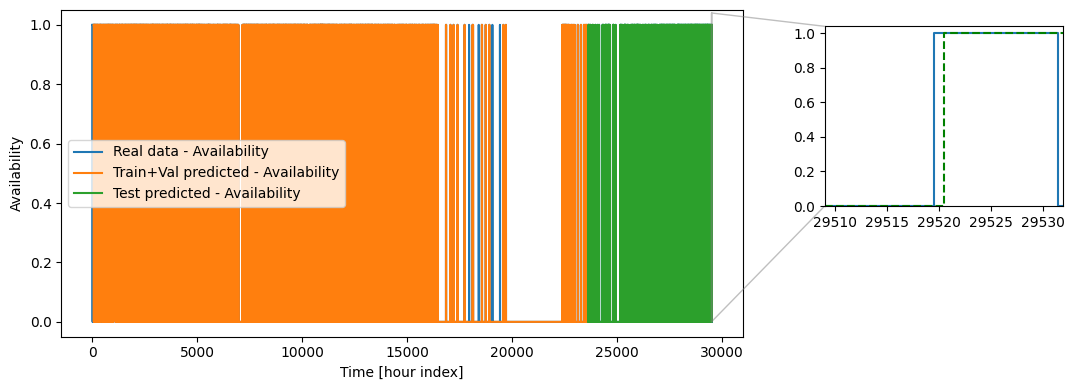

In [7]:
# -----------------------------
# Availability plot (FULL + last-24h inset) — kept
# -----------------------------
plt.figure(figsize=(12, 4))

real_np  = avail_series.flatten()
train_np = trainPredictPlot_avail.flatten()
test_np  = testPredictPlot_avail.flatten()
x_full   = np.arange(len(real_np))

plt.step(x_full, real_np, where="mid", label="Real data - Availability")
plt.step(x_full, train_np, where="mid", label="Train+Val predicted - Availability")
plt.step(x_full, test_np, where="mid", label="Test predicted - Availability")

plt.xlabel("Time [hour index]")
plt.ylabel("Availability")
plt.legend()

zoom_len = 24
x1 = max(0, len(real_np) - zoom_len)
x2 = len(real_np)
idx = slice(x1, x2)

x_zoom    = x_full[idx]
real_zoom = real_np[idx]
test_zoom = test_np[idx]

y1 = np.nanmin([real_zoom.min(), np.nanmin(test_zoom)])
y2 = np.nanmax([real_zoom.max(), np.nanmax(test_zoom)]) + 0.04

ax = plt.gca()
axins = ax.inset_axes([1.12, 0.40, 0.35, 0.55])
axins.step(x_zoom, real_zoom, where="mid", label="Real (last 24h)")
axins.step(x_zoom, test_zoom, where="mid", label="Forecast",
           color="green", linestyle="--")
axins.set_xlim(x_zoom[0], x_zoom[-1])
axins.set_ylim(y1, y2)
ax.indicate_inset_zoom(axins)

plt.tight_layout()
plt.show()

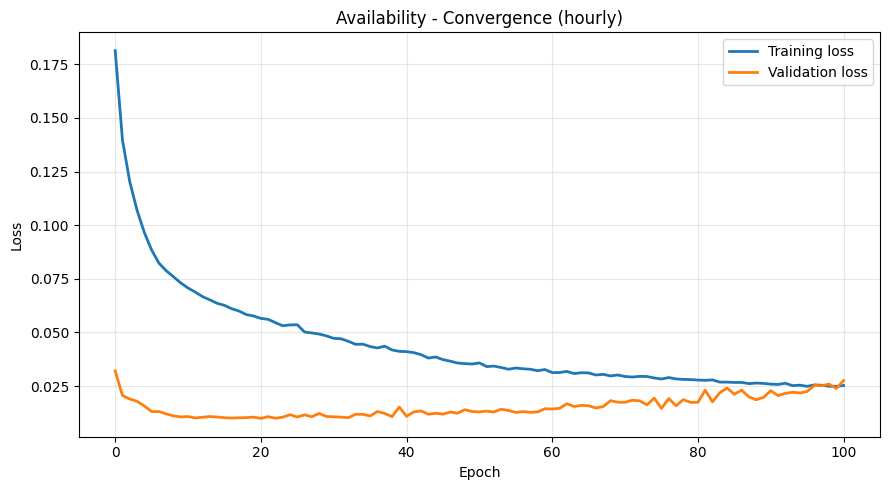

TH (threshold) = 0.38499999999999995
Train prevalence (mean availability) = 0.48427245020866394
Val prevalence   (mean availability) = 0.035132382065057755
Test prevalence  (mean availability) = 0.252502977848053
Pred prob stats (val): 0.0006471286178566515 0.9972319602966309 mean= 0.038269322365522385


/tmp/ipython-input-4258513121.py:108: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  forecast_hours_avail = pd.date_range(


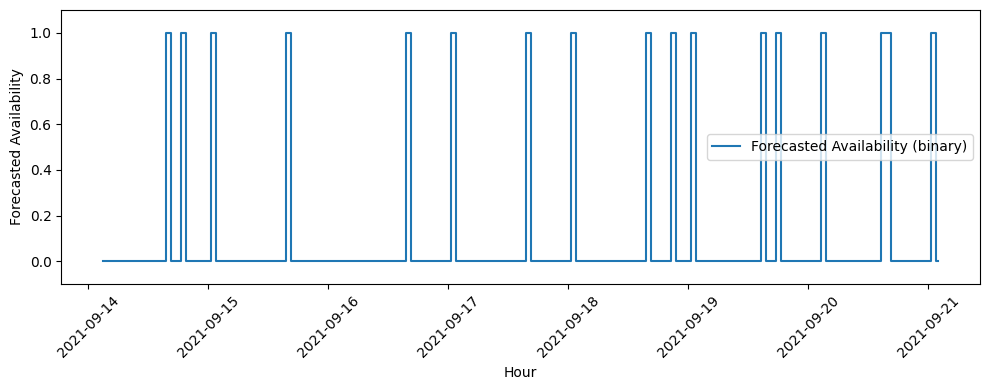

Forecast prob min/max: 0.0019513770239427686 0.6852602362632751
Share of predicted 1s: 0.10119047619047619


In [8]:
# -----------------------------
# 3.7 Convergence plot (train + validation) for availability — kept
# -----------------------------
plt.figure(figsize=(9, 5))
plt.plot(history_avail.history["loss"], linewidth=2)
if "val_loss" in history_avail.history and history_avail.history["val_loss"] is not None:
    plt.plot(history_avail.history["val_loss"], linewidth=2)
    plt.legend(["Training loss", "Validation loss"])
else:
    plt.legend(["Training loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Availability - Convergence (hourly)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("TH (threshold) =", TH)
print("Train prevalence (mean availability) =", float(np.mean(y_train_avail)))
print("Val prevalence   (mean availability) =", float(np.mean(y_val_avail)))
print("Test prevalence  (mean availability) =", float(np.mean(y_test_avail)))

print("Pred prob stats (val):",
      float(np.min(y_pred_val_prob)), float(np.max(y_pred_val_prob)),
      "mean=", float(np.mean(y_pred_val_prob)))

# -----------------------------
# 3.8 Forecast availability for next whole period (iterative) — CORRECTED
# -----------------------------

# indices for availability lag features
avail_lag_cols = sorted(
    [c for c in feature_cols_avail if c.startswith("availability_lag")],
    key=lambda s: int(s.replace("availability_lag",""))
)
avail_lag_idx = [feature_cols_avail.index(c) for c in avail_lag_cols]

# indices for calendar features
idx_hour_of_day = feature_cols_avail.index("hour_of_day")
idx_day_type    = feature_cols_avail.index("day_type")
idx_month       = feature_cols_avail.index("month")
idx_hod_sin = feature_cols_avail.index("hod_sin")
idx_hod_cos = feature_cols_avail.index("hod_cos")
idx_dow_sin = feature_cols_avail.index("dow_sin")
idx_dow_cos = feature_cols_avail.index("dow_cos")
idx_mon_sin = feature_cols_avail.index("mon_sin")
idx_mon_cos = feature_cols_avail.index("mon_cos")

def scale_one_feature(raw_value, col_name):
    j = feature_cols_avail.index(col_name)
    return (raw_value - scaler_av.mean_[j]) / scaler_av.scale_[j]

# start from last known window (SCALED)
last_sequence_avail = scaled_full_feats_avail[-seq_len:].reshape((1, seq_len, n_features_avail)).copy()

forecast_prob = []
forecast_bin  = []

t0 = kWh_full["hour"].iloc[-1] + pd.Timedelta(hours=1)

for step in range(Forecast_period):
    # 1) predict probability
    p = float(model_avail.predict(last_sequence_avail, verbose=0)[0, 0])
    b = int(p >= TH)
    forecast_prob.append(p)
    forecast_bin.append(b)

    # 2) roll window
    last_sequence_avail = np.roll(last_sequence_avail, -1, axis=1)

    # 3) build new row from previous row (keeps non-updated features stable)
    old_row = last_sequence_avail[0, -2, :].copy()
    new_row = old_row.copy()

    # 4) advance calendar features correctly
    ts = (t0 + pd.Timedelta(hours=step)).tz_convert("UTC") if hasattr(t0, "tz_convert") else (t0 + pd.Timedelta(hours=step))
    hod = ts.hour
    dow = ts.dayofweek
    mon = ts.month
    day_type = int(dow >= 5)

    new_row[idx_hour_of_day] = scale_one_feature(hod, "hour_of_day")
    new_row[idx_day_type]    = scale_one_feature(day_type, "day_type")
    new_row[idx_month]       = scale_one_feature(mon, "month")

    new_row[idx_hod_sin] = scale_one_feature(np.sin(2*np.pi*hod/24), "hod_sin")
    new_row[idx_hod_cos] = scale_one_feature(np.cos(2*np.pi*hod/24), "hod_cos")
    new_row[idx_dow_sin] = scale_one_feature(np.sin(2*np.pi*dow/7),  "dow_sin")
    new_row[idx_dow_cos] = scale_one_feature(np.cos(2*np.pi*dow/7),  "dow_cos")
    new_row[idx_mon_sin] = scale_one_feature(np.sin(2*np.pi*(mon-1)/12), "mon_sin")
    new_row[idx_mon_cos] = scale_one_feature(np.cos(2*np.pi*(mon-1)/12), "mon_cos")

    # 5) shift availability lags
    for k in range(len(avail_lag_idx)-1, 0, -1):
        new_row[avail_lag_idx[k]] = old_row[avail_lag_idx[k-1]]

    # 6) write NEW lag1 in SCALED space
    lag1_col = feature_cols_avail.index("availability_lag1")
    b_scaled = (b - scaler_av.mean_[lag1_col]) / scaler_av.scale_[lag1_col]
    new_row[avail_lag_idx[0]] = b_scaled

    # 7) commit row
    last_sequence_avail[0, -1, :] = new_row

# define these ONCE, after loop
forecast_binary = np.array(forecast_bin, dtype=int)

forecast_hours_avail = pd.date_range(
    start=kWh_full["hour"].iloc[-1] + pd.Timedelta(hours=1),
    periods=Forecast_period, freq="H", tz="UTC"
)

# Plot (force correct y-limits for binary)
plt.figure(figsize=(10, 4))
plt.step(forecast_hours_avail, forecast_binary, where="mid", label="Forecasted Availability (binary)")
plt.ylim(-0.1, 1.1)
plt.xlabel("Hour")
plt.ylabel("Forecasted Availability")
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

forecast_prob_arr = np.array(forecast_prob, dtype=float)
print("Forecast prob min/max:", forecast_prob_arr.min(), forecast_prob_arr.max())
print("Share of predicted 1s:", forecast_binary.mean())

In [14]:
# -----------------------------
# Save availability results to Excel — kept (same sheets)
# -----------------------------
excel_out = "/content/LSTM_all_results.xlsx"

metrics_df = pd.DataFrame([{
    "model": "availability",
    "seq_len": seq_len,
    "train_size_ratio": 0.60,

    # Binary (decision) errors
    "train_mse_bin": float(train_mse_avail),
    "test_mse_bin": float(test_mse_avail),
    "train_rmse_bin": float(train_rmse_avail),
    "test_rmse_bin": float(test_rmse_avail),
    "train_mae_bin": float(train_mae_avail),
    "test_mae_bin": float(test_mae_avail),
    "train_r2_bin": float(train_r2_avail),
    "test_r2_bin": float(test_r2_avail),

    # Probability (Brier-style) errors
    "train_mse_prob": float(train_mse_avail_prob),
    "test_mse_prob": float(test_mse_avail_prob),
    "train_mae_prob": float(train_mae_avail_prob),
    "test_mae_prob": float(test_mae_avail_prob),

    "test_auc": float(test_auc),
    "test_f1": float(test_f1),
    "test_precision": float(test_prec),
    "test_recall": float(test_rec),

    "threshold_TH": float(TH),
    "epochs": len(history_avail.history.get("loss", []))
}])

loss_df = pd.DataFrame({
    "epoch": np.arange(1, len(history_avail.history["loss"]) + 1),
    "train_loss": history_avail.history["loss"]
})
if "val_loss" in history_avail.history:
    loss_df["val_loss"] = history_avail.history["val_loss"]

pred_full_df = pd.DataFrame({
    "hour": kWh_full["hour"],
    "availability_real": kWh_full["availability"].values.astype(int),
    "availability_trainval_pred_bin": trainPredictPlot_avail.flatten(),
    "availability_test_pred_bin": testPredictPlot_avail.flatten(),
})

test_eval_df = pd.DataFrame({
    "hour": kWh_full["hour"].iloc[test_hour_idx_avail].values,
    "y_test_avail": y_test_avail.flatten(),
    "y_pred_test_avail_bin": y_pred_test_avail.astype(int),
    "y_pred_test_avail_prob": y_pred_test_prob.astype(float)
})

forecast_24h_df = pd.DataFrame({
    "hour": forecast_hours_avail,
    "availability_forecast_prob": np.asarray(forecast_prob).astype(float),
    "availability_forecast_bin": np.asarray(forecast_binary).astype(int)
})

kWh_full_export = kWh_full.copy()

with pd.ExcelWriter(excel_out, engine="openpyxl") as writer:
    make_excel_safe(metrics_df).to_excel(writer, sheet_name="metrics", index=False)
    make_excel_safe(loss_df).to_excel(writer, sheet_name="convergence_loss", index=False)
    make_excel_safe(pred_full_df).to_excel(writer, sheet_name="predictions_full", index=False)
    make_excel_safe(test_eval_df).to_excel(writer, sheet_name="test_eval", index=False)
    make_excel_safe(forecast_24h_df).to_excel(writer, sheet_name="forecast_next_24h", index=False)
    make_excel_safe(kWh_full_export).to_excel(writer, sheet_name="kWh_full_input", index=False)

print("All availability results saved to:", excel_out)
display(FileLink(excel_out))

/tmp/ipython-input-2625978664.py:34: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df2[c]):


All availability results saved to: /content/LSTM_all_results.xlsx


/content/LSTM_all_results.xlsx

In [15]:
# ============================================================
# 4) kWhDelivered model (regression) — UNCHANGED (Huber + log1p)
# ============================================================
kwh_features = [
    "kWhDelivered", "availability", "day_type", "month",
    "hod_sin","hod_cos","dow_sin","dow_cos","mon_sin","mon_cos",
    "occupancy_count","connected_minutes"
] + [c for c in kWh_full.columns if c.startswith("kWhDelivered_lag")] \
  + [c for c in kWh_full.columns if c.startswith("kWhDelivered_roll_")] \
  + [c for c in kWh_full.columns if c.startswith("availability_lag")] \
  + [c for c in kWh_full.columns if c.startswith("availability_roll_")]

train_df = kWh_full.iloc[:n_train_raw].copy()
val_df   = kWh_full.iloc[n_train_raw:n_train_raw+n_val_raw].copy()
test_df  = kWh_full.iloc[n_train_raw+n_val_raw:].copy()

scaler_kwh = StandardScaler()
train_k = train_df[kwh_features].copy()
val_k   = val_df[kwh_features].copy()
test_k  = test_df[kwh_features].copy()

train_k["kWh_log"] = np.log1p(train_k["kWhDelivered"].values)
val_k["kWh_log"]   = np.log1p(val_k["kWhDelivered"].values)
test_k["kWh_log"]  = np.log1p(test_k["kWhDelivered"].values)

cols_to_scale_kwh = [c for c in kwh_features if c != "kWhDelivered"]
train_k[cols_to_scale_kwh] = scaler_kwh.fit_transform(train_k[cols_to_scale_kwh])
val_k[cols_to_scale_kwh]   = scaler_kwh.transform(val_k[cols_to_scale_kwh])
test_k[cols_to_scale_kwh]  = scaler_kwh.transform(test_k[cols_to_scale_kwh])

X_train_kwh, y_train_kwh = create_sequences(
    train_k[kwh_features].values.astype(np.float32),
    seq_length=seq_len,
    target_col=kwh_features.index("kWhDelivered")
)
X_val_kwh,   y_val_kwh   = create_sequences(
    val_k[kwh_features].values.astype(np.float32),
    seq_length=seq_len,
    target_col=kwh_features.index("kWhDelivered")
)
X_test_kwh,  y_test_kwh  = create_sequences(
    test_k[kwh_features].values.astype(np.float32),
    seq_length=seq_len,
    target_col=kwh_features.index("kWhDelivered")
)

y_train_kwh = train_k["kWh_log"].values[seq_len:seq_len+len(y_train_kwh)].astype(np.float32)
y_val_kwh   = val_k["kWh_log"].values[seq_len:seq_len+len(y_val_kwh)].astype(np.float32)
y_test_kwh  = test_k["kWh_log"].values[seq_len:seq_len+len(y_test_kwh)].astype(np.float32)

test_start_kwh = n_train_raw + n_val_raw + seq_len
test_hour_idx_kwh = np.arange(test_start_kwh, test_start_kwh + len(y_test_kwh))

n_features_kwh = X_train_kwh.shape[2]

inp = keras.Input(shape=(seq_len, n_features_kwh))
x = layers.Conv1D(96, kernel_size=5, padding="causal", activation="relu")(inp)
x = layers.Dropout(0.2)(x)
x = layers.Bidirectional(layers.LSTM(96, return_sequences=True))(x)
x = layers.Dropout(0.2)(x)
x = layers.Bidirectional(layers.LSTM(48))(x)
x = layers.Dense(96, activation="relu")(x)
x = layers.Dropout(0.2)(x)
out = layers.Dense(1)(x)
model_kwh = keras.Model(inp, out)

In [16]:
model_kwh.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss=keras.losses.Huber(delta=0.5)
)
cb_kwh = [
    keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=60, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=15, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("/content/best_kwh.keras", monitor="val_loss", save_best_only=True),
]

history_kwh = model_kwh.fit(
    X_train_kwh, y_train_kwh,
    validation_data=(X_val_kwh, y_val_kwh),
    epochs=200, batch_size=256, verbose=1,
    callbacks=cb_kwh
)

Epoch 1/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.1095 - val_loss: 0.0091 - learning_rate: 5.0000e-04
Epoch 2/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0894 - val_loss: 0.0078 - learning_rate: 5.0000e-04
Epoch 3/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0713 - val_loss: 0.0045 - learning_rate: 5.0000e-04
Epoch 4/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0616 - val_loss: 0.0039 - learning_rate: 5.0000e-04
Epoch 5/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0577 - val_loss: 0.0039 - learning_rate: 5.0000e-04
Epoch 6/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0554 - val_loss: 0.0036 - learning_rate: 5.0000e-04
Epoch 7/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0540 - val_loss: 0.0037 - learning_rate: 5.0000e-04
Epoch 8/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0529 - val_loss: 0.0035 - learning_rate: 5.0000e-04
Epoch 9/200
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0520 - val_loss: 0.0035 - 

552/552 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step
183/183 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

=== kWhDelivered metrics ===
Train MSE: 0.823280930519104
Test  MSE: 0.41364404559135437
Train RMSE: 0.9073482961460302
Test  RMSE: 0.6431516505392444
Train MAE: 0.41270911693573
Test  MAE: 0.22533728182315826
Train R2: 0.6204077005386353
Test  R2: 0.4799309968948364


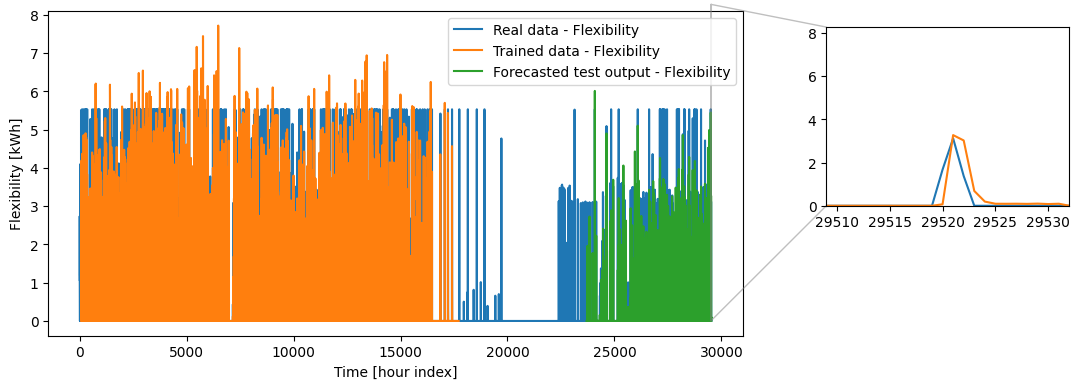

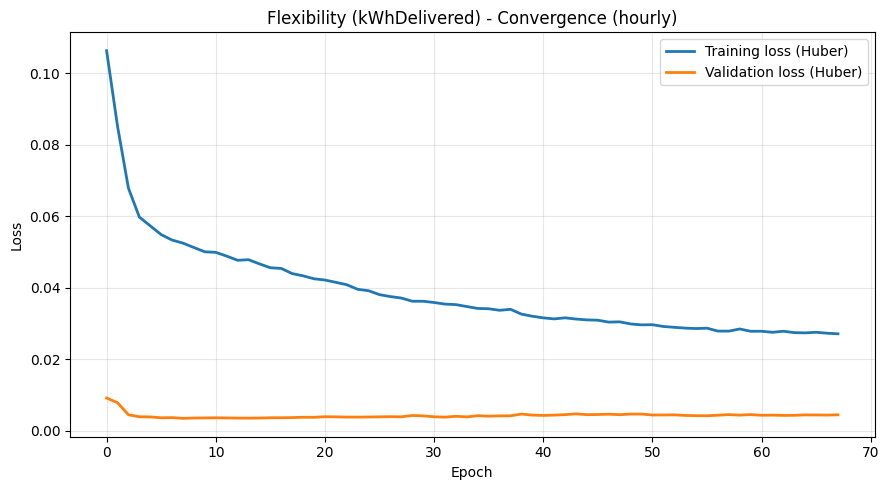

In [17]:
y_pred_train_kwh_log = model_kwh.predict(X_train_kwh).flatten()
y_pred_test_kwh_log  = model_kwh.predict(X_test_kwh).flatten()

y_train_kwh_inv = np.expm1(y_train_kwh)
y_test_kwh_inv  = np.expm1(y_test_kwh)
y_pred_train_kwh_inv = np.expm1(y_pred_train_kwh_log)
y_pred_test_kwh_inv  = np.expm1(y_pred_test_kwh_log)

y_pred_train_kwh_inv = np.clip(y_pred_train_kwh_inv, 0, None)
y_pred_test_kwh_inv  = np.clip(y_pred_test_kwh_inv, 0, None)

train_mse_kwh = mean_squared_error(y_train_kwh_inv, y_pred_train_kwh_inv)
test_mse_kwh  = mean_squared_error(y_test_kwh_inv,  y_pred_test_kwh_inv)
train_rmse_kwh = math.sqrt(train_mse_kwh)
test_rmse_kwh  = math.sqrt(test_mse_kwh)
train_mae_kwh = mean_absolute_error(y_train_kwh_inv, y_pred_train_kwh_inv)
test_mae_kwh  = mean_absolute_error(y_test_kwh_inv,  y_pred_test_kwh_inv)
train_r2_kwh  = r2_score(y_train_kwh_inv, y_pred_train_kwh_inv)
test_r2_kwh   = r2_score(y_test_kwh_inv,  y_pred_test_kwh_inv)

print("\n=== kWhDelivered metrics ===")
print("Train MSE:", train_mse_kwh)
print("Test  MSE:", test_mse_kwh)
print("Train RMSE:", train_rmse_kwh)
print("Test  RMSE:", test_rmse_kwh)
print("Train MAE:", train_mae_kwh)
print("Test  MAE:", test_mae_kwh)
print("Train R2:", train_r2_kwh)
print("Test  R2:", test_r2_kwh)

# -----------------------------
# 4.5 Shifted plotting: kWhDelivered (whole series) — kept
# -----------------------------
kwh_series = kWh_full["kWhDelivered"].values.reshape(-1, 1).astype(float)

trainPredictPlot_kwh = np.empty_like(kwh_series, dtype=float); trainPredictPlot_kwh[:] = np.nan
testPredictPlot_kwh  = np.empty_like(kwh_series, dtype=float); testPredictPlot_kwh[:]  = np.nan

train_size_kwh = len(y_train_kwh_inv)
test_size_kwh  = len(y_test_kwh_inv)

trainPredictPlot_kwh[seq_len:seq_len + train_size_kwh, 0] = y_pred_train_kwh_inv

test_start_kwh_full = n_train_raw + n_val_raw + seq_len
testPredictPlot_kwh[test_start_kwh_full:test_start_kwh_full + test_size_kwh, 0] = y_pred_test_kwh_inv

avail_series_int = kWh_full["availability"].values.astype(int)
for i in range(len(avail_series_int)):
    if avail_series_int[i] == 0:
        if not np.isnan(trainPredictPlot_kwh[i]):
            trainPredictPlot_kwh[i] = 0
        if not np.isnan(testPredictPlot_kwh[i]):
            testPredictPlot_kwh[i] = 0
    if not np.isnan(trainPredictPlot_kwh[i]) and trainPredictPlot_kwh[i] < 0:
        trainPredictPlot_kwh[i] = 0
    if not np.isnan(testPredictPlot_kwh[i]) and testPredictPlot_kwh[i] < 0:
        testPredictPlot_kwh[i] = 0

plt.figure(figsize=(12, 4))
plt.plot(kwh_series, label="Real data - Flexibility")
plt.plot(trainPredictPlot_kwh, label="Trained data - Flexibility")
plt.plot(testPredictPlot_kwh, label="Forecasted test output - Flexibility")
plt.xlabel("Time [hour index]")
plt.ylabel("Flexibility [kWh]")
plt.legend()

real_np  = kwh_series.flatten()
test_np  = np.array(testPredictPlot_kwh).flatten()
x_full = np.arange(len(real_np))

zoom_len = 24
x1 = max(0, len(real_np) - zoom_len)
x2 = len(real_np)
idx = slice(x1, x2)
x_zoom = x_full[idx]
real_zoom = real_np[idx]
test_pred_zoom = test_np[idx]

y1 = np.nanmin([real_zoom.min(), np.nanmin(test_pred_zoom)])
y2 = np.nanmax([real_zoom.max(), np.nanmax(test_pred_zoom)]) + 5

ax = plt.gca()
axins = ax.inset_axes([1.12, 0.40, 0.35, 0.55])
axins.plot(x_zoom, real_zoom, label="Real (last 24 hours)")
axins.plot(x_zoom, test_pred_zoom, label="Forecast")
axins.set_xlim(x_zoom[0], x_zoom[-1])
axins.set_ylim(y1, y2)
ax.indicate_inset_zoom(axins)
plt.tight_layout()
plt.show()
# -----------------------------
# 4.7 Convergence plot (train + validation) for kWhDelivered — kept
# -----------------------------
plt.figure(figsize=(9, 5))
plt.plot(history_kwh.history["loss"], linewidth=2)
if "val_loss" in history_kwh.history and history_kwh.history["val_loss"] is not None:
    plt.plot(history_kwh.history["val_loss"], linewidth=2)
    plt.legend(["Training loss (Huber)", "Validation loss (Huber)"])
else:
    plt.legend(["Training loss (Huber)"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Flexibility (kWhDelivered) - Convergence (hourly)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipython-input-3707231769.py:59: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  forecast_hours_kwh = pd.date_range(


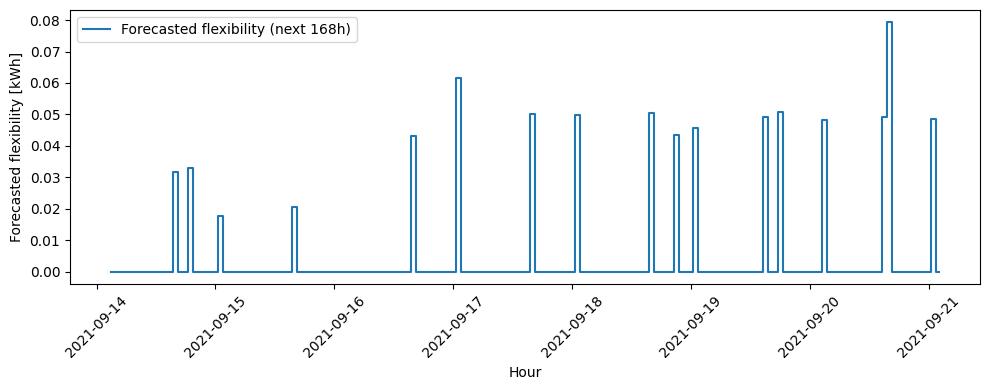

In [18]:
# -----------------------------
# 4.8 Forecast kWhDelivered
# -----------------------------

scaled_feats_kwh_full = np.vstack([
    train_k[kwh_features].values.astype(np.float32),
    val_k[kwh_features].values.astype(np.float32),
    test_k[kwh_features].values.astype(np.float32)
])

last_sequence_kwh = scaled_feats_kwh_full[-seq_len:].reshape((1, seq_len, n_features_kwh))

# --- MUST be defined BEFORE the loop ---
forecast_binary_arr = np.array(forecast_binary, dtype=int)[:Forecast_period]

lst_output_kwh_log = []
for step in range(Forecast_period):
    pred = model_kwh.predict(last_sequence_kwh, verbose=0)
    lst_output_kwh_log.append(float(pred[0, 0]))

    # roll window
    last_sequence_kwh = np.roll(last_sequence_kwh, -1, axis=1)

    old_row = last_sequence_kwh[0, -2, :].copy()
    new_row = old_row.copy()

    # 1) update main kWhDelivered feature (index 0)
    new_kwh = float(np.expm1(pred[0, 0]))
    new_kwh = max(0.0, new_kwh)
    new_row[0] = new_kwh

    # 2) shift kWh lag features
    kwh_lag_cols = sorted([c for c in kwh_features if c.startswith("kWhDelivered_lag")],
                          key=lambda s: int(s.replace("kWhDelivered_lag","")))
    kwh_lag_idx = [kwh_features.index(c) for c in kwh_lag_cols]

    for k in range(len(kwh_lag_idx)-1, 0, -1):
        new_row[kwh_lag_idx[k]] = old_row[kwh_lag_idx[k-1]]
    new_row[kwh_lag_idx[0]] = new_kwh  # lag1

    # 3) update availability feature using forecast
    if "availability" in kwh_features:
        idx_av = kwh_features.index("availability")
        new_row[idx_av] = float(forecast_binary_arr[step])

    # commit
    last_sequence_kwh[0, -1, :] = new_row

forecasted_kWh = np.expm1(np.array(lst_output_kwh_log)).reshape(-1, 1)
forecasted_kWh = np.clip(forecasted_kWh, 0, None)
forecasted_kWh[forecast_binary_arr.reshape(-1, 1) == 0] = 0.0

# Use the availability forecast (must also be length H)
forecast_binary_arr = np.array(forecast_binary).astype(int)  # forecast_binary must be length H now
forecast_binary_arr = forecast_binary_arr[:Forecast_period]

forecasted_kWh[forecast_binary_arr.reshape(-1, 1) == 0] = 0.0

forecast_hours_kwh = pd.date_range(
    start=kWh_full["hour"].iloc[-1] + pd.Timedelta(hours=1),
    periods=Forecast_period, freq="H", tz="UTC"
)

plt.figure(figsize=(10, 4))
plt.step(forecast_hours_kwh, forecasted_kWh.flatten(), where="mid", label=f"Forecasted flexibility (next {Forecast_period}h)")
plt.xlabel("Hour")
plt.ylabel("Forecasted flexibility [kWh]")
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()


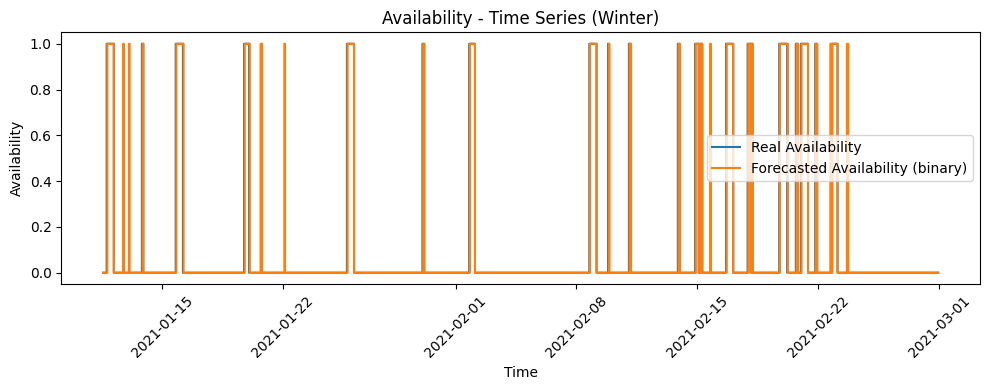

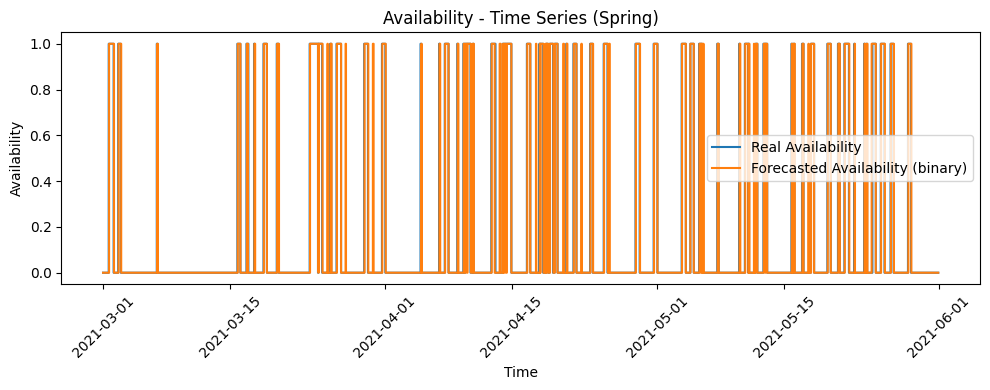

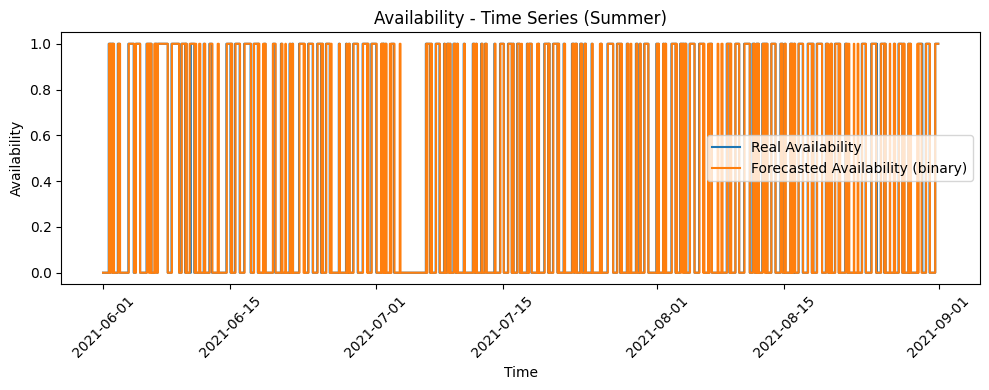

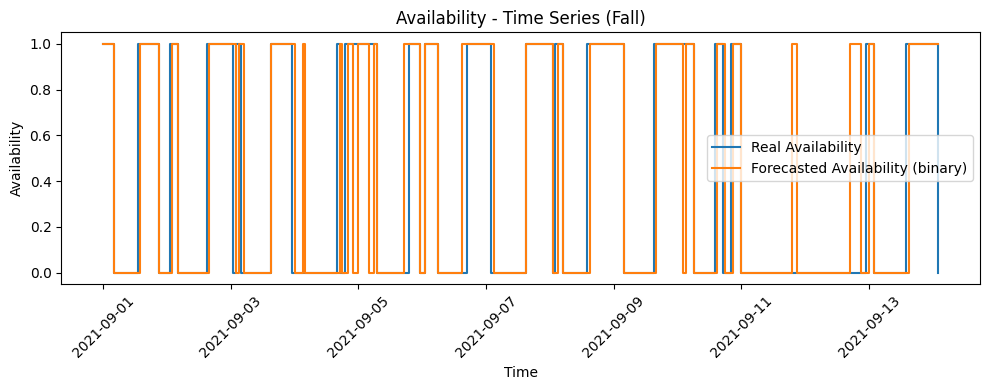

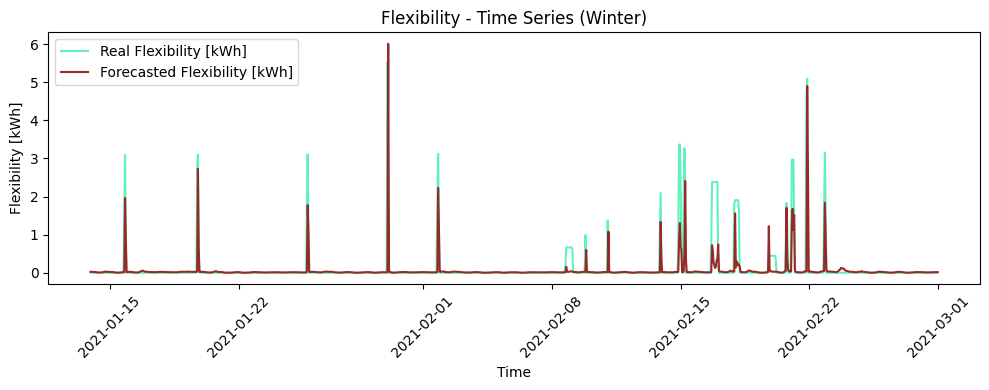

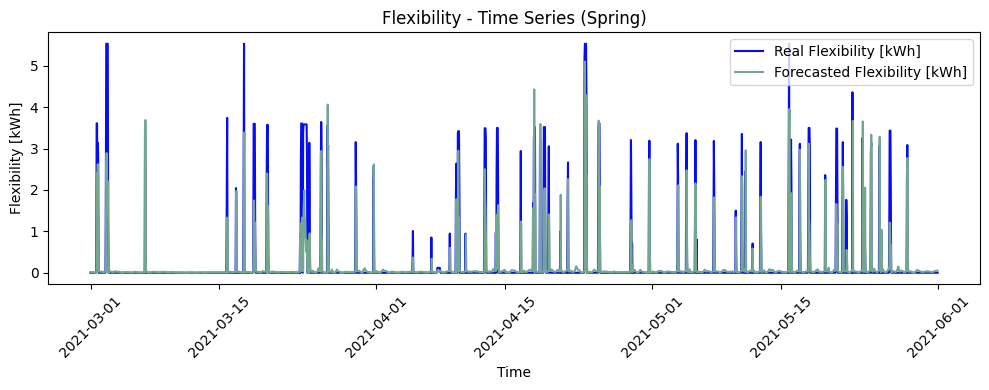

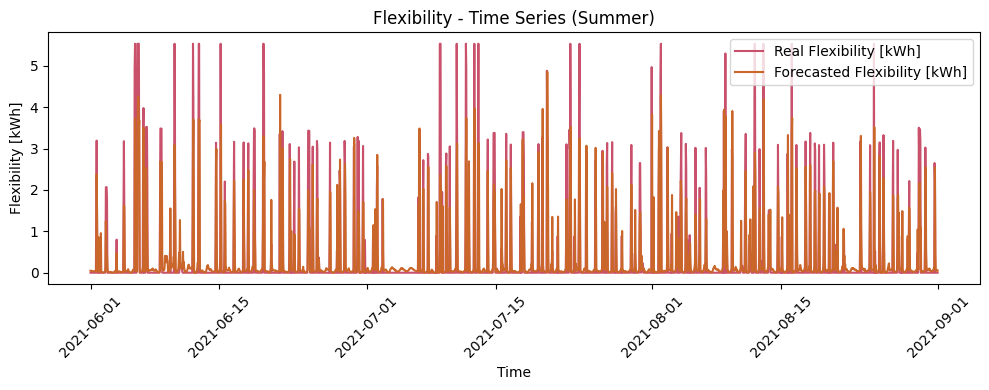

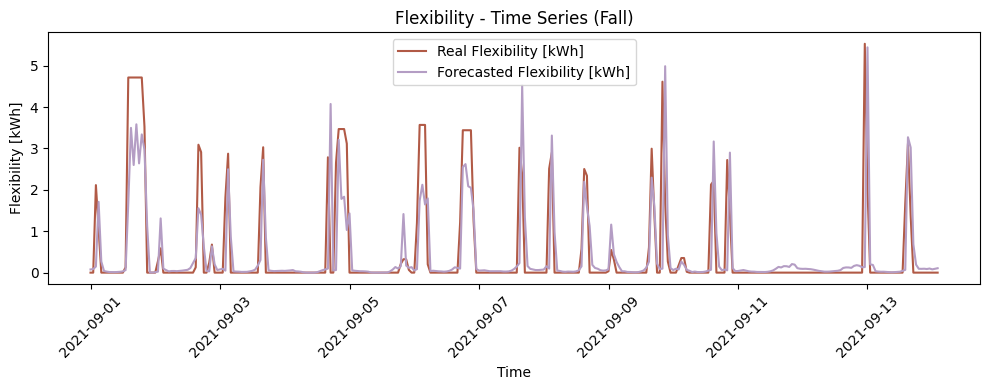

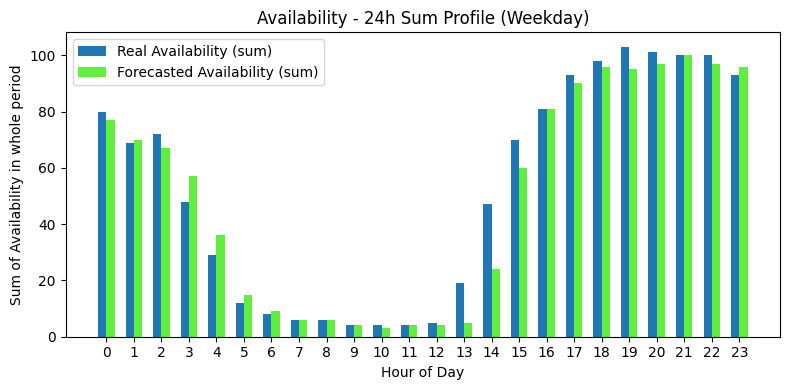

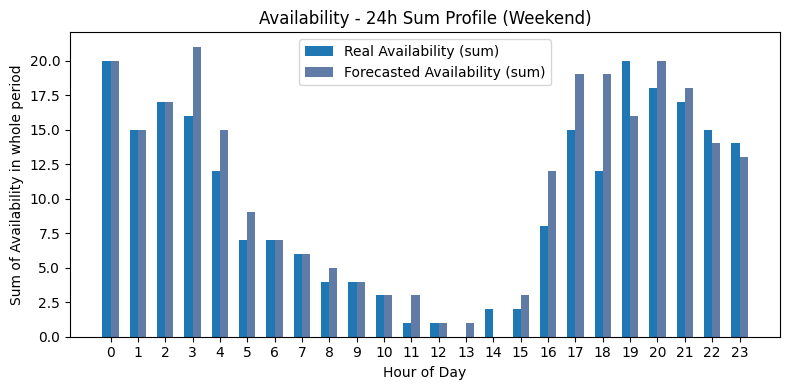

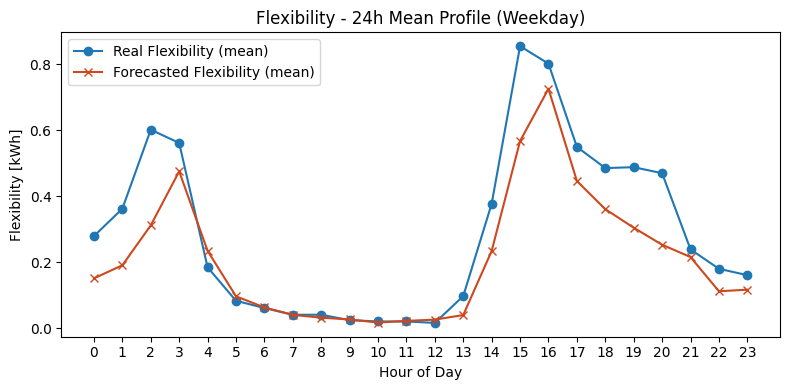

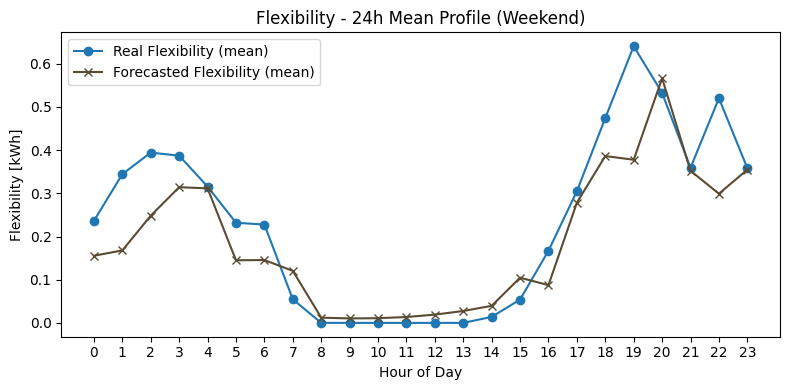


Seasonal metrics - Availability (LSTM, continuous output)
    Group       MSE      RMSE       MAE        R2
0  Winter  0.029103  0.170595  0.064688  0.692516
1  Spring  0.045649  0.213657  0.085756  0.702011
2  Summer  0.090356  0.300593  0.159274  0.612576
3    Fall  0.085752  0.292834  0.163510  0.646208

Seasonal metrics - Flexibility [kWh]
    Group       MSE      RMSE       MAE        R2
0  Winter  0.175893  0.419396  0.100810  0.357686
1  Spring  0.354062  0.595031  0.180227  0.492581
2  Summer  0.549292  0.741143  0.312025  0.475976
3    Fall  0.714472  0.845265  0.370732  0.461141

Day-type metrics - Availability (LSTM, continuous output)
     Group       MSE      RMSE       MAE        R2
0  Weekday  0.061823  0.248642  0.113427  0.704001
1  Weekend  0.059921  0.244788  0.112997  0.503727

Day-type metrics - Flexibility [kWh]
     Group       MSE      RMSE       MAE        R2
0  Weekday  0.395979  0.629269  0.230807  0.499008
1  Weekend  0.457343  0.676272  0.211806  0.432062


In [19]:
# ============================================================
# 5) SEASONAL AND DAY-TYPE ANALYSIS (FIGURES & TABLES) — kept
# ============================================================
import random

used_colors = []
def random_color(min_diff=0.98):
    for _ in range(10000):
        color = np.random.rand(3)
        if all(np.linalg.norm(color - uc) > min_diff for uc in used_colors):
            used_colors.append(color)
            return tuple(color)
    return tuple(np.random.rand(3))

def month_to_season(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Spring"
    elif m in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

season_order = ["Winter", "Spring", "Summer", "Fall"]
daytype_map = {0: "Weekday", 1: "Weekend"}

test_hours_av = kWh_full["hour"].iloc[test_hour_idx_avail].values
results_avail = pd.DataFrame({
    "hour": pd.to_datetime(test_hours_av),
    "real": y_test_avail.flatten(),
    "pred_prob": y_pred_test_prob.flatten(),
    "pred_bin":  y_pred_test_avail.flatten().astype(int)
})
results_avail["month"] = pd.to_datetime(results_avail["hour"]).dt.month
results_avail["season"] = results_avail["month"].apply(month_to_season)
results_avail["day_type"] = kWh_full["day_type"].iloc[test_hour_idx_avail].values
results_avail["hour_of_day"] = pd.to_datetime(results_avail["hour"]).dt.hour

test_hours_k = kWh_full["hour"].iloc[test_hour_idx_kwh].values
results_kwh = pd.DataFrame({
    "hour": pd.to_datetime(test_hours_k),
    "real": y_test_kwh_inv.flatten(),
    "pred": y_pred_test_kwh_inv.flatten()
})
results_kwh["month"] = pd.to_datetime(results_kwh["hour"]).dt.month
results_kwh["season"] = results_kwh["month"].apply(month_to_season)
results_kwh["day_type"] = kWh_full["day_type"].iloc[test_hour_idx_kwh].values
results_kwh["hour_of_day"] = pd.to_datetime(results_kwh["hour"]).dt.hour
results_kwh["avail_real"] = kWh_full["availability"].iloc[test_hour_idx_kwh].values

results_avail["pred_last_hour"] = np.roll(results_avail["real"].values, 1)
results_avail["pred_prev_day"]  = np.roll(results_avail["real"].values, 24)
results_kwh["pred_last_hour"] = np.roll(results_kwh["real"].values, 1)
results_kwh["pred_prev_day"]  = np.roll(results_kwh["real"].values, 24)

results_avail.loc[results_avail.index[0], "pred_last_hour"] = np.nan
results_kwh.loc[results_kwh.index[0], "pred_last_hour"] = np.nan
results_avail.loc[results_avail.index[:24], "pred_prev_day"] = np.nan
results_kwh.loc[results_kwh.index[:24], "pred_prev_day"] = np.nan

# B) TIME-SERIES BY SEASON — kept
for season in season_order:
    df_s = results_avail[results_avail["season"] == season]
    if df_s.empty:
        continue
    plt.figure(figsize=(10, 4))
    plt.step(df_s["hour"], df_s["real"], where="post", label="Real Availability")
    plt.step(df_s["hour"], df_s["pred_bin"], where="post", label="Forecasted Availability (binary)")
    plt.xlabel("Time")
    plt.ylabel("Availability")
    plt.title(f"Availability - Time Series ({season})")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

for season in season_order:
    df_s = results_kwh[results_kwh["season"] == season]
    if df_s.empty:
        continue
    plt.figure(figsize=(10, 4))
    plt.plot(df_s["hour"], df_s["real"], label="Real Flexibility [kWh]", color=random_color())
    plt.plot(df_s["hour"], df_s["pred"], label="Forecasted Flexibility [kWh]", color=random_color())
    plt.xlabel("Time")
    plt.ylabel("Flexibility [kWh]")
    plt.title(f"Flexibility - Time Series ({season})")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

# C) WEEKDAY / WEEKEND 24h PROFILES — kept
for dt_val, dt_name in daytype_map.items():
    df_dt = results_avail[results_avail["day_type"] == dt_val]
    if df_dt.empty:
        continue
    sum_real_av = df_dt.groupby("hour_of_day")["real"].sum()
    sum_pred_av = df_dt.groupby("hour_of_day")["pred_bin"].sum()

    plt.figure(figsize=(8, 4))
    plt.bar(sum_real_av.index - 0.15, sum_real_av.values, width=0.3, label="Real Availability (sum)")
    plt.bar(sum_pred_av.index + 0.15, sum_pred_av.values, width=0.3, label="Forecasted Availability (sum)", color=random_color())
    plt.xlabel("Hour of Day")
    plt.ylabel("Sum of Availability in whole period")
    plt.title(f"Availability - 24h Sum Profile ({dt_name})")
    plt.xticks(range(0, 24))
    plt.legend()
    plt.tight_layout()
    plt.show()

for dt_val, dt_name in daytype_map.items():
    df_dt = results_kwh[results_kwh["day_type"] == dt_val]
    if df_dt.empty:
        continue
    mean_real_flex = df_dt.groupby("hour_of_day")["real"].mean()
    mean_pred_flex = df_dt.groupby("hour_of_day")["pred"].mean()

    plt.figure(figsize=(8, 4))
    plt.plot(mean_real_flex.index, mean_real_flex.values, marker="o", label="Real Flexibility (mean)")
    plt.plot(mean_pred_flex.index, mean_pred_flex.values, marker="x", label="Forecasted Flexibility (mean)", color=random_color())
    plt.xlabel("Hour of Day")
    plt.ylabel("Flexibility [kWh]")
    plt.title(f"Flexibility - 24h Mean Profile ({dt_name})")
    plt.xticks(range(0, 24))
    plt.legend()
    plt.tight_layout()
    plt.show()

# D) SEASONAL ERROR TABLES — kept
def compute_metric_row(df, label, pred_col="pred"):
    if df.empty:
        return None
    mse = mean_squared_error(df["real"], df[pred_col])
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(df["real"], df[pred_col])
    r2 = r2_score(df["real"], df[pred_col])
    return {"Group": label, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

rows_avail_season = []
for season in season_order:
    r = compute_metric_row(results_avail[results_avail["season"] == season], season, pred_col="pred_prob")
    if r is not None:
        rows_avail_season.append(r)
season_metrics_avail_df = pd.DataFrame(rows_avail_season)
print("\nSeasonal metrics - Availability (LSTM, continuous output)")
print(season_metrics_avail_df)

rows_kwh_season = []
for season in season_order:
    r = compute_metric_row(results_kwh[results_kwh["season"] == season], season)
    if r is not None:
        rows_kwh_season.append(r)
season_metrics_kwh_df = pd.DataFrame(rows_kwh_season)
print("\nSeasonal metrics - Flexibility [kWh]")
print(season_metrics_kwh_df)

season_metrics_avail_df.to_excel("/content/season_metrics_availability.xlsx", index=False)
season_metrics_kwh_df.to_excel("/content/season_metrics_flexibility.xlsx", index=False)

# E) DAY-TYPE ERROR TABLES — kept
rows_avail_daytype = []
for dt_val, dt_name in daytype_map.items():
    r = compute_metric_row(results_avail[results_avail["day_type"] == dt_val], dt_name, pred_col="pred_prob")
    if r is not None:
        rows_avail_daytype.append(r)
daytype_metrics_avail_df = pd.DataFrame(rows_avail_daytype)
print("\nDay-type metrics - Availability (LSTM, continuous output)")
print(daytype_metrics_avail_df)

rows_kwh_daytype = []
for dt_val, dt_name in daytype_map.items():
    r = compute_metric_row(results_kwh[results_kwh["day_type"] == dt_val], dt_name)
    if r is not None:
        rows_kwh_daytype.append(r)
daytype_metrics_kwh_df = pd.DataFrame(rows_kwh_daytype)
print("\nDay-type metrics - Flexibility [kWh]")
print(daytype_metrics_kwh_df)

daytype_metrics_avail_df.to_excel("/content/daytype_metrics_availability.xlsx", index=False)
daytype_metrics_kwh_df.to_excel("/content/daytype_metrics_flexibility.xlsx", index=False)


In [20]:

# ============================================================
# 6) Error metrics comparison table — kept
# ============================================================
methods = ["LSTM", "Last Hour", "Same Hour Prev Day"]
targets = ["Availability", "Flexibility"]

error_metrics = {
    method: {
        target: {
            dt_name: {season: None for season in season_order}
            for dt_name in daytype_map.values()
        }
        for target in targets
    }
    for method in methods
}

def _pick_first_existing(df, candidates, df_name="df"):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(
        f"None of the candidate columns exist in {df_name}: {candidates}\n"
        f"Existing columns: {df.columns.tolist()}"
    )

def compute_and_store_metrics(df_real, df_pred, method, target, day_type, season):
    real = np.array(df_real, dtype=float)
    pred = np.array(df_pred, dtype=float)

    mask = ~np.isnan(real) & ~np.isnan(pred)
    if mask.sum() == 0:
        return

    real_valid = real[mask]
    pred_valid = pred[mask]

    mse = mean_squared_error(real_valid, pred_valid)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(real_valid, pred_valid)
    r2 = r2_score(real_valid, pred_valid)

    error_metrics[method][target][day_type][season] = {
        "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2
    }

avail_pred_col = _pick_first_existing(
    results_avail,
    candidates=["pred_prob", "pred_bin", "pred", "availability_pred_prob", "availability_pred_bin"],
    df_name="results_avail"
)
kwh_pred_col = _pick_first_existing(
    results_kwh,
    candidates=["pred", "kWh_pred", "pred_kwh", "kWhDelivered_pred", "y_pred"],
    df_name="results_kwh"
)

print("Section 6: using availability pred column =", avail_pred_col)
print("Section 6: using kWh pred column         =", kwh_pred_col)

for season in season_order:
    for dt_val, dt_name in daytype_map.items():
        df_av = results_avail[(results_avail["season"] == season) & (results_avail["day_type"] == dt_val)]
        if not df_av.empty:
            compute_and_store_metrics(df_av["real"], df_av[avail_pred_col], "LSTM", "Availability", dt_name, season)
            compute_and_store_metrics(df_av["real"], df_av["pred_last_hour"], "Last Hour", "Availability", dt_name, season)
            compute_and_store_metrics(df_av["real"], df_av["pred_prev_day"], "Same Hour Prev Day", "Availability", dt_name, season)

        df_k = results_kwh[(results_kwh["season"] == season) & (results_kwh["day_type"] == dt_val)]
        if not df_k.empty:
            compute_and_store_metrics(df_k["real"], df_k[kwh_pred_col], "LSTM", "Flexibility", dt_name, season)
            compute_and_store_metrics(df_k["real"], df_k["pred_last_hour"], "Last Hour", "Flexibility", dt_name, season)
            compute_and_store_metrics(df_k["real"], df_k["pred_prev_day"], "Same Hour Prev Day", "Flexibility", dt_name, season)

rows = []
for method in methods:
    for target in targets:
        for dt_name in daytype_map.values():
            for season in season_order:
                m = error_metrics[method][target][dt_name][season]
                if m is None:
                    continue
                rows.append({
                    "Method": method,
                    "Target": target,
                    "Day Type": dt_name,
                    "Season": season,
                    "MSE": m["MSE"],
                    "RMSE": m["RMSE"],
                    "MAE": m["MAE"],
                    "R2": m["R2"],
                })

metrics_df = pd.DataFrame(rows)
print("\nComparison table - methods x target x day-type x season (test set)")
print(metrics_df)

metrics_df.to_excel("/content/comparison_table_error_metrics.xlsx", index=False)
print("\nComparison Table saved at: /content/comparison_table_error_metrics.xlsx")

Section 6: using availability pred column = pred_prob
Section 6: using kWh pred column         = pred

Comparison table - methods x target x day-type x season (test set)
                Method        Target Day Type  Season       MSE      RMSE  \
0                 LSTM  Availability  Weekday  Winter  0.028773  0.169626   
1                 LSTM  Availability  Weekday  Spring  0.047428  0.217779   
2                 LSTM  Availability  Weekday  Summer  0.091410  0.302340   
3                 LSTM  Availability  Weekday    Fall  0.076601  0.276769   
4                 LSTM  Availability  Weekend  Winter  0.029913  0.172953   
5                 LSTM  Availability  Weekend  Spring  0.041135  0.202817   
6                 LSTM  Availability  Weekend  Summer  0.087681  0.296110   
7                 LSTM  Availability  Weekend    Fall  0.106626  0.326536   
8                 LSTM   Flexibility  Weekday  Winter  0.127046  0.356435   
9                 LSTM   Flexibility  Weekday  Spring  0.377

In [21]:
# ============================================================
# 7) One consolidated Excel with all upgraded outputs — kept
# ============================================================
excel_out_final = "/content/EV_forecasting_upgraded_results.xlsx"

test_pred_df = pd.DataFrame({
    "hour": kWh_full["hour"].iloc[test_hour_idx_avail].values,
    "availability_real": np.asarray(y_test_avail).astype(int).reshape(-1),
    "availability_pred_bin": np.asarray(y_pred_test_avail).astype(int).reshape(-1),
    "availability_pred_prob_for_auc": np.asarray(y_pred_test_prob).astype(float).reshape(-1)
})

test_pred_kwh_df = pd.DataFrame({
    "hour": kWh_full["hour"].iloc[test_hour_idx_kwh].values,
    "kWh_real": np.asarray(y_test_kwh_inv).astype(float).reshape(-1),
    "kWh_pred": np.asarray(y_pred_test_kwh_inv).astype(float).reshape(-1)
})

_avail_fc_prob = np.asarray(forecast_prob).astype(float).reshape(-1)

forecast_whole_period = pd.DataFrame({
    "hour": forecast_hours_kwh,
    "availability_forecast_prob": _avail_fc_prob[:len(forecast_hours_kwh)],
    "availability_forecast_bin": np.asarray(forecast_binary_arr).astype(int).reshape(-1)[:len(forecast_hours_kwh)],
    "kWh_forecast_next_whole_period": np.asarray(forecasted_kWh).astype(float).reshape(-1)[:len(forecast_hours_kwh)]
})

final_metrics = pd.DataFrame([{
    "availability_test_mse_bin": float(test_mse_avail),
    "availability_test_rmse_bin": float(test_rmse_avail),
    "availability_test_mae_bin": float(test_mae_avail),
    "availability_test_r2_bin": float(test_r2_avail),

    "availability_test_mse_prob": float(test_mse_avail_prob),
    "availability_test_mae_prob": float(test_mae_avail_prob),

    "availability_test_auc": float(test_auc),
    "availability_test_f1": float(test_f1),

    "kWh_test_mse": float(test_mse_kwh),
    "kWh_test_rmse": float(test_rmse_kwh),
    "kWh_test_mae": float(test_mae_kwh),
    "kWh_test_r2": float(test_r2_kwh),

    "seq_len": int(seq_len),
    "threshold_TH": float(TH)
}])

with pd.ExcelWriter(excel_out_final, engine="openpyxl") as writer:
    make_excel_safe(kWh_full).to_excel(writer, sheet_name="hourly_input", index=False)
    make_excel_safe(final_metrics).to_excel(writer, sheet_name="metrics_summary", index=False)
    make_excel_safe(test_pred_df).to_excel(writer, sheet_name="test_availability", index=False)
    make_excel_safe(test_pred_kwh_df).to_excel(writer, sheet_name="test_kwh", index=False)
    make_excel_safe(forecast_whole_period).to_excel(writer, sheet_name="forecast_whole_period", index=False)

    if "season_metrics_avail_df" in globals():
        make_excel_safe(season_metrics_avail_df).to_excel(writer, sheet_name="season_metrics_avail", index=False)
    if "season_metrics_kwh_df" in globals():
        make_excel_safe(season_metrics_kwh_df).to_excel(writer, sheet_name="season_metrics_kwh", index=False)
    if "daytype_metrics_avail_df" in globals():
        make_excel_safe(daytype_metrics_avail_df).to_excel(writer, sheet_name="daytype_metrics_avail", index=False)
    if "daytype_metrics_kwh_df" in globals():
        make_excel_safe(daytype_metrics_kwh_df).to_excel(writer, sheet_name="daytype_metrics_kwh", index=False)

    if "metrics_df" in globals():
        make_excel_safe(metrics_df).to_excel(writer, sheet_name="comparison_table", index=False)

print("Saved consolidated upgraded results:", excel_out_final)
display(FileLink(excel_out_final))

/tmp/ipython-input-2625978664.py:34: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(df2[c]):


Saved consolidated upgraded results: /content/EV_forecasting_upgraded_results.xlsx


/content/EV_forecasting_upgraded_results.xlsx